# ② 打球速度・打球角度と本塁打確率

## 研究目的と仮説

打球速度と打球角度の組合せが、本塁打確率とどのように関連するかを検討する。速度・角度の二乗や交互作用を追加することで、基本的なロジスティック回帰より予測性能が改善するという仮説を設定した。

## 使用データと対象定義

MLB Statcastの2025年4〜5月のレギュラーシーズン投球から、`description == hit_into_play`かつ`launch_speed`、`launch_angle`、`events`が観測されている打球を選ぶ。本塁打もこの分類に含まれる。ファウル・空振りは対象外とする。

打球発生後の計測情報に基づく条件付き結果推定であり、打席前の本塁打予測とは区別する。計測値の欠損による対象選択の影響も分析上の制約として扱う。

In [1]:
# リポジトリ内の共通処理を読み込む
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / 'src'))
from mlb_portfolio.data import *
from mlb_portfolio.analysis import *

# 集計表の表示範囲を設定する（分析対象の行数・列数は変更しない）
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 35)


## 1. データ品質と対象選択

取得済みデータを読み込み、選択条件による件数変化、要約統計、欠損率と評価期間を確認する。取得ログ・データ定義は[出典と利用条件](../DATA_SOURCES.md)を参照。

In [2]:
# 取得済みキャッシュを優先して投球データを読み込む
raw = statcast_data()
# 計測済みインプレー打球を選び、本塁打ラベルと二次特徴量を作成する
df = batted_balls(raw)
# 対象選択の件数、要約統計、欠損率、時間分割ごとの陽性率を確認する
quality(raw, df, 'hr')

game_type
R    234985
Name: pitches, dtype: int64

Pitch keys duplicated: 0


,rows,stage
0,234985,deduplicated_source
1,234985,regular_season
2,41310,in_play
3,41158,eligible


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pitch_type,41158,16,FF,12209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
game_date,41158,61,2025-05-14,865,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_speed,41158.0,<NA>,<NA>,<NA>,89.302896,6.162805,34.3,85.3,90.2,94.1,103.3
release_pos_x,41158.0,<NA>,<NA>,<NA>,-0.899511,1.888818,-4.93,-2.23,-1.62,0.25,4.53
release_pos_z,41158.0,<NA>,<NA>,<NA>,5.756406,0.512881,1.21,5.49,5.82,6.07,7.47
player_name,41158,641,"Littell, Zack",220,NaN,NaN,NaN,NaN,NaN,NaN,NaN
batter,41158.0,<NA>,<NA>,<NA>,652770.912824,50628.95979,455117.0,641857.0,666158.0,679032.0,810938.0
pitcher,41158.0,<NA>,<NA>,<NA>,646618.989868,51548.133035,434378.0,621107.0,663795.0,676962.0,820862.0
events,41158,16,field_out,24487,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,41158,1,hit_into_play,41158,NaN,NaN,NaN,NaN,NaN,NaN,NaN


description
hit_into_play    41158
Name: count, dtype: int64

,split,n,positive_rate,start,end
0,train,19887,0.040278,2025-04-01,2025-04-30
1,validation,10139,0.044284,2025-05-01,2025-05-15
2,test,11132,0.040963,2025-05-16,2025-05-31


## 2. 探索的分析と統計的検討

分布・集計・可視化から傾向を確認し、訓練データのみで統計モデルを推定する。係数と区間は探索的な関連として解釈する。

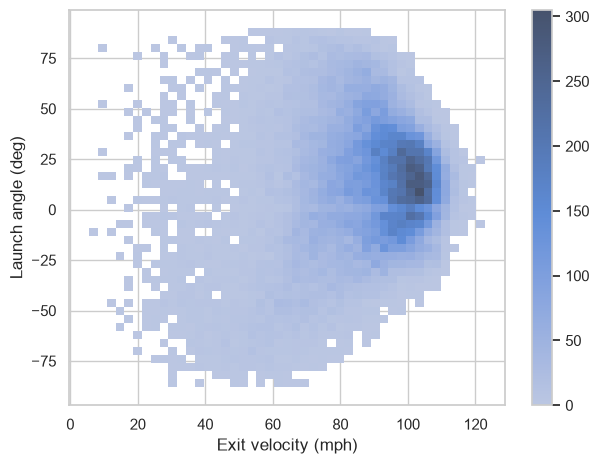

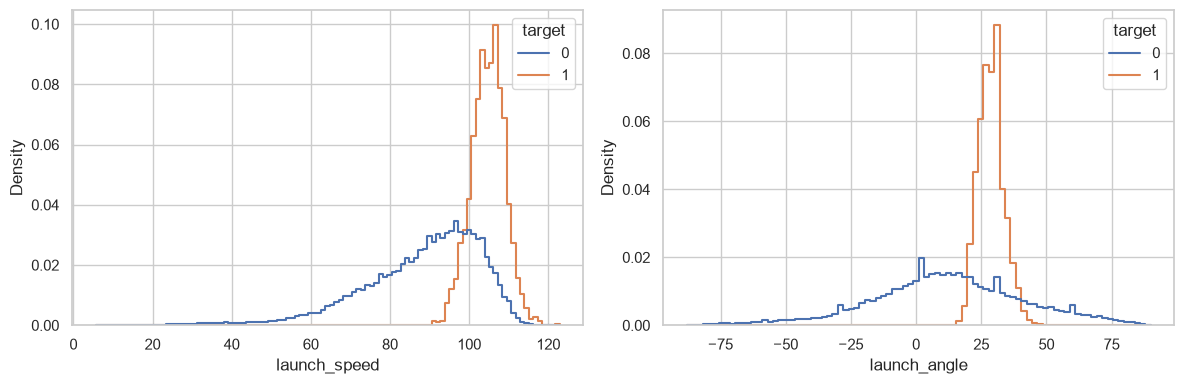

mean  size  sum   lower95   upper95
labin    evbin                                              
(20, 30] (110, 115]  0.887931   116  103  0.817666  0.933327
         (105, 110]  0.722054   662  478  0.686722  0.754825
(30, 40] (105, 110]  0.695652   230  160  0.633375  0.751501
         (100, 105]  0.395738   657  260  0.359056  0.433633
(20, 30] (100, 105]  0.328970  1146  377  0.302379  0.356705
(40, 50] (105, 110]  0.227273    44   10  0.128419  0.369924
(30, 40] (95, 100]   0.113750   800   91  0.093569  0.137622
(10, 20] (110, 115]  0.105991   217   23  0.071671  0.154018
(20, 30] (95, 100]   0.098392  1057  104  0.081864  0.117828
(40, 50] (100, 105]  0.047368   190    9  0.025118  0.087559
(10, 20] (105, 110]  0.035126   911   32  0.024990  0.049167
(30, 40] (90, 95]    0.023320   729   17  0.014610  0.037027

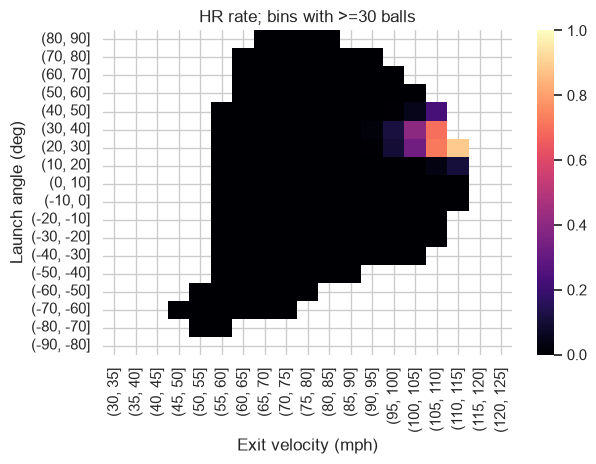

,coefficient,lower95,upper95,p_value
Intercept,-9.788127,-11.060636,-8.515617,2.329119e-51
ev10,5.860712,4.419552,7.301872,1.580164e-15
la10,7.550459,6.434781,8.666137,3.731408e-40
I(ev10 ** 2),-0.606336,-1.040377,-0.172294,6.181798e-03
I(la10 ** 2),-3.086661,-3.432614,-2.740707,1.794683e-68
ev10:la10,-0.549556,-1.132394,0.033282,6.459582e-02


Training-only exploratory associations; game-cluster robust SE; no causal interpretation or multiple-testing correction.


In [3]:
# 打球の分布と速度・角度別の本塁打率を可視化する
hr_eda(df)
# 訓練データのみで二乗・交互作用を含む統計モデルを推定する
inference(df, 'hr')

## 3. モデル比較と評価方法

2025年4月を訓練、5月1〜15日を検証、5月16〜31日を固定テストとする。定数確率、基本・特徴量追加ロジスティック回帰、設定の異なるRandom Forestを比較し、検証log lossで選択する。

基本特徴は打球速度と角度とし、それぞれの二乗と両者の積を追加する。飛距離や推定wOBAなどの結果に近い追加情報は使用しない。前処理はPipeline内で訓練データから学習し、乱数を42に固定する。

本塁打のクラス不均衡を踏まえ、ROC-AUC、average precision、log loss、Brier score、閾値0.5のAccuracyを記録する。固定テストでは選択モデルと定数確率を評価し、試合単位の対応付きブートストラップ400回でlog loss差の95%区間を算出する。

,task,model,split,n_train,n_eval,features,ROC_AUC,PR_AUC_AP,log_loss,Brier,accuracy_0.5
0,hr,baseline_mean,validation,19887,10139,"launch_speed,launch_angle",0.500000,0.044284,0.181530,0.042339,0.955716
1,hr,logistic_basic,validation,19887,10139,"launch_speed,launch_angle",0.942872,0.399706,0.107264,0.032088,0.955913
2,hr,logistic_extended,validation,19887,10139,"launch_speed,launch_angle,speed_angle,angle2,s...",0.981645,0.709477,0.070241,0.021610,0.969228
3,hr,rf_leaf20,validation,19887,10139,"launch_speed,launch_angle,speed_angle,angle2,s...",0.984323,0.765260,0.062019,0.019396,0.972680
4,hr,rf_leaf50,validation,19887,10139,"launch_speed,launch_angle,speed_angle,angle2,s...",0.984745,0.767491,0.061544,0.019306,0.972778
5,hr,rf_leaf50,test,19887,11132,NaN,0.982345,0.711187,0.063040,0.019690,0.972422
6,hr,baseline_mean,test,19887,11132,NaN,0.500000,0.040963,0.170999,0.039285,0.959037


Validation-selected: rf_leaf50


,comparison,metric,lower95,upper95,clusters,bootstrap
0,rf_leaf50 minus baseline_mean,log_loss,-0.118199,-0.098187,215,400


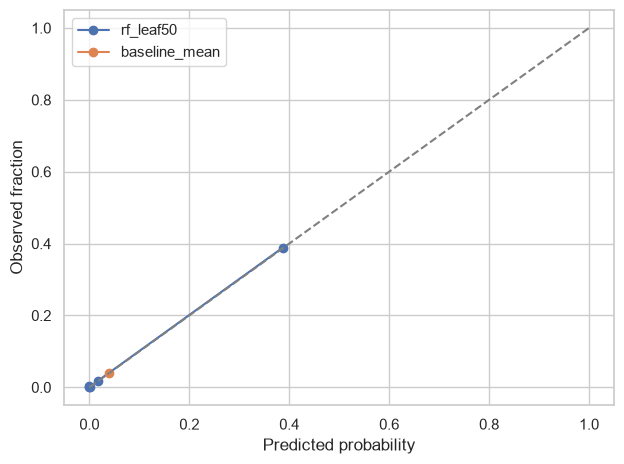

In [4]:
# 検証データでモデルを固定し、テスト指標・図・実験CSVを出力する
results = evaluate(df, 'hr')

## 4. 結果の解釈と限界

基本ロジスティック回帰に二乗・積を追加すると、検証log lossは0.107から0.070へ改善した。検証で選択したRandom Forest（最小葉50）のテストlog lossは0.063、定数確率は0.171、ROC-AUCは0.982、average precisionは0.711だった。

105〜110mph・20〜30度の領域では478/662打球（72.2%）が本塁打だった。ただし全期間の探索で見出した領域であり、独立標本で確認した最適角度ではない。統計モデルの速度×角度の係数区間は0を含み、個別交互作用の有意性と特徴量追加による予測改善は区別する。

計測欠損152打球の除外、球場・打球方向・天候などの未観測要因が制約となる。高い識別性能は打球後の情報によるものであり、打席前の予測精度を示さない。Wilson区間は記述用とし、別年度への外部検証は未実施。詳細は[分析レポート](../reports/REPORT.md)に記載する。